# Red funcional para la lluvia satelital del Valle del Cauca, 1981-2003

Preprocesamiento de estaciones y satélite, curvas funcionales, FPCA y red funcional con cabezas lineal, MLP y KAN. Escribe en `data/processed/`, `data/baddata/`, `figures/item4_red/` y `predicciones_estaciones_reservadas.csv`.

In [1]:
PREPROCESAR = True
BUSCAR = False

In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from IPython.display import Image, display

from src import curvas, datos, entrenamiento, evaluacion, interpretacion, preprocesamiento
from src.comun import FIG


def figura(*nombres):
    for nombre in nombres:
        display(Image(filename=str(FIG / f"{nombre}.png")))

## Preprocesamiento

In [3]:
preprocesamiento.ejecutar(forzar=PREPROCESAR)

Preprocesamiento desde data/raw/ (forzado)


  satelite: 6 s


  depurar: 28 s


  exportar: 2 s


  faltantes: 693 s


D:\repos_equipo\_corrida_limpia\red_funcional\src\validacion.py:735: RuntimeWarning: All-NaN slice encountered
  error_l2_rel_mediana=float(np.nanmedian(e[:, 0])), error_l2_rel_p90=float(np.nanquantile(e[:, 0], 0.9)),
D:\repos_equipo\venv_kan\Lib\site-packages\numpy\lib\nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
D:\repos_equipo\_corrida_limpia\red_funcional\src\validacion.py:736: RuntimeWarning: All-NaN slice encountered
  abs_error_total_pct_mediana=float(np.nanmedian(np.abs(e[:, 1]))),
D:\repos_equipo\_corrida_limpia\red_funcional\src\validacion.py:737: RuntimeWarning: All-NaN slice encountered
  sesgo_total_pct_mediana=float(np.nanmedian(e[:, 1]))))


... (2 outputs left out)

  auditoria: 1 s


  decimas: 0 s


prueba de fuga: APROBADA 
  fuga: 27 s


  sensibilidad: 362 s


## Curvas funcionales

In [4]:
ctx = datos.cargar()
vistas = curvas.construir(ctx)
print(f"K por VCG: estaciones {ctx.K_Y}, satélite {ctx.K_X}; Gram con {ctx.nq} nodos de Gauss-Legendre")
vistas

K por VCG: estaciones 8, satélite 11; Gram con 64 nodos de Gauss-Legendre


,vista,curvas,estaciones
0,entrenamiento,2140,173
1,prueba,789,121
2,ciegas,565,31


## FPCA

In [5]:
varianza, pliegues = curvas.ajustar_fpca(ctx)
print(f"Referencia de picos: log10(λ relativo) = {curvas.referencia_picos(ctx):.1f}")
display(varianza.head(8), pliegues)

Referencia de picos: log10(λ relativo) = 2.0


,M,autovalor,varianza_explicada_acumulada
0,1,140.103992,0.636189
1,2,26.379161,0.755972
2,3,15.290490,0.825404
3,4,10.754886,0.874240
4,5,8.363565,0.912217
5,6,7.148790,0.944679
6,7,6.299065,0.973282
7,8,5.884002,1.000000


,pliegue,entrena,curvas_entrenamiento,valida,curvas_validacion
0,1,1981-1988,1088,1989-1990,290
1,2,1981-1990,1378,1991-1992,257
2,3,1981-1992,1635,1993-1994,251
3,4,1981-1994,1886,1995-1996,254


## Red funcional

RMSE de la KAN sintética: 0.0083


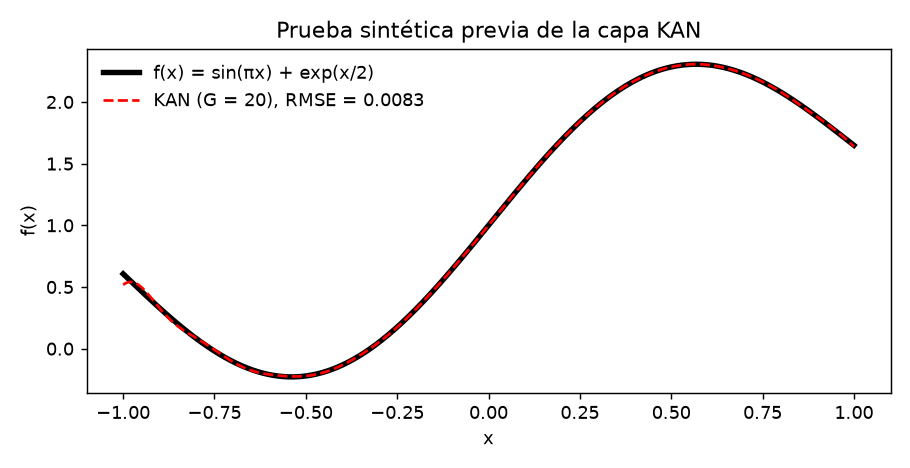

In [6]:
print(f"RMSE de la KAN sintética: {entrenamiento.prueba_sintetica(ctx):.4f}")
figura("kan_sintetica")

## Búsqueda de hiperparámetros

In [7]:
parametros = entrenamiento.buscar(ctx, buscar=BUSCAR)
parametros

,cabeza,parametros_cabeza,parametros_codificador,parametros_totales,candidatos_evaluados,configuraciones_distintas,corridas_busqueda,epocas_ajuste_final,configuracion
0,lineal,45,66,111,28,17,68,281,"{""cabeza"": ""lineal"", ""l1"": 0.0, ""lam_w"": 0.01,..."
1,mlp,453,66,519,28,21,84,222,"{""ancho"": 32, ""cabeza"": ""mlp"", ""drop"": 0.0, ""l..."
2,kan,440,66,506,28,21,84,116,"{""G"": 10, ""ancho"": 0, ""cabeza"": ""kan"", ""drop"":..."


## Ajuste final

In [8]:
cv_final, seleccion = entrenamiento.ajuste_final(ctx)
print("Cabeza del CSV de predicciones:", ctx.CABEZA_CSV)
display(seleccion, cv_final)

Cabeza del CSV de predicciones: mlp


,cabeza,cv_rel_media,cv_rel_sd,dif_media_con_la_mejor,ee_dif,empata_con_la_mejor,parametros,parametros_efectivos,elegida_csv
0,lineal,0.604836,0.061802,0.175420,0.013392,False,111,111.0,False
1,mlp,0.429416,0.050167,0.000000,0.000000,True,519,519.0,True
2,kan,0.477427,0.045822,0.048011,0.003674,False,506,363.0,False


,cabeza,pliegue,validacion,fases_validacion,perdida_val,perdida_climatologia,perdida_rel,epoca_mejor
0,lineal,1,1989-1990,La Niña / neutro,138.339775,213.175455,0.648948,274
1,lineal,2,1991-1992,El Niño / El Niño,152.327129,228.637304,0.666239,288
2,lineal,3,1993-1994,neutro / neutro,124.472370,221.701945,0.561440,111
3,lineal,4,1995-1996,La Niña / neutro,119.553749,220.287778,0.542716,413
4,mlp,1,1989-1990,La Niña / neutro,97.396148,213.175455,0.456883,288
5,mlp,2,1991-1992,El Niño / El Niño,110.411089,228.637304,0.482909,183
6,mlp,3,1993-1994,neutro / neutro,82.209555,221.701945,0.370811,244
7,mlp,4,1995-1996,La Niña / neutro,89.670258,220.287778,0.407060,200
8,kan,1,1989-1990,La Niña / neutro,108.757083,213.175455,0.510176,123
9,kan,2,1991-1992,El Niño / El Niño,119.074900,228.637304,0.520803,79


,nivel,cabeza,cambio,parametros,media_val,sd_val,discrepancia
0,1,mlp,ancho=16,295,0.454709,0.054616,0.037288
1,1,kan,G=5,306,0.476169,0.051753,0.037288
2,2,mlp,ancho=32,519,0.429416,0.050167,0.025048
3,2,kan,G=10,506,0.477427,0.045822,0.025048
4,3,mlp,ancho=64,967,0.432850,0.048460,0.019648
5,3,kan,G=22,986,0.473394,0.032356,0.019648


,lambda_L1,peso_entropia,media_val,sd_val,aristas_activas_media,aristas_totales
0,0.000,0.0,0.468770,0.060024,33.75,40
1,0.001,2.0,0.501330,0.094598,33.75,40
2,0.010,2.0,0.477427,0.045822,27.00,40
3,0.100,2.0,0.515723,0.041808,6.00,40


,fase,curvas,varianza_captada_base_propia,varianza_captada_base_comun,coseno_angulo_principal_minimo,coseno_angulo_principal_medio,distancia_media_fase_a_media_comun_rel,cv_kan_decodificador_comun,cv_kan_decodificador_por_fase,cv_diferencia_pareada_media,cv_diferencia_pareada_sd,por_fase_mejora_concluyente
0,nino,653,0.921843,0.914126,0.612770,0.921864,0.073869,0.477427,0.520636,0.043209,0.008153,False
1,nina,553,0.922325,0.901373,0.590826,0.873879,0.090449,0.477427,0.520636,0.043209,0.008153,False
2,neutro,934,0.921107,0.910221,0.757863,0.935851,0.066185,0.477427,0.520636,0.043209,0.008153,False


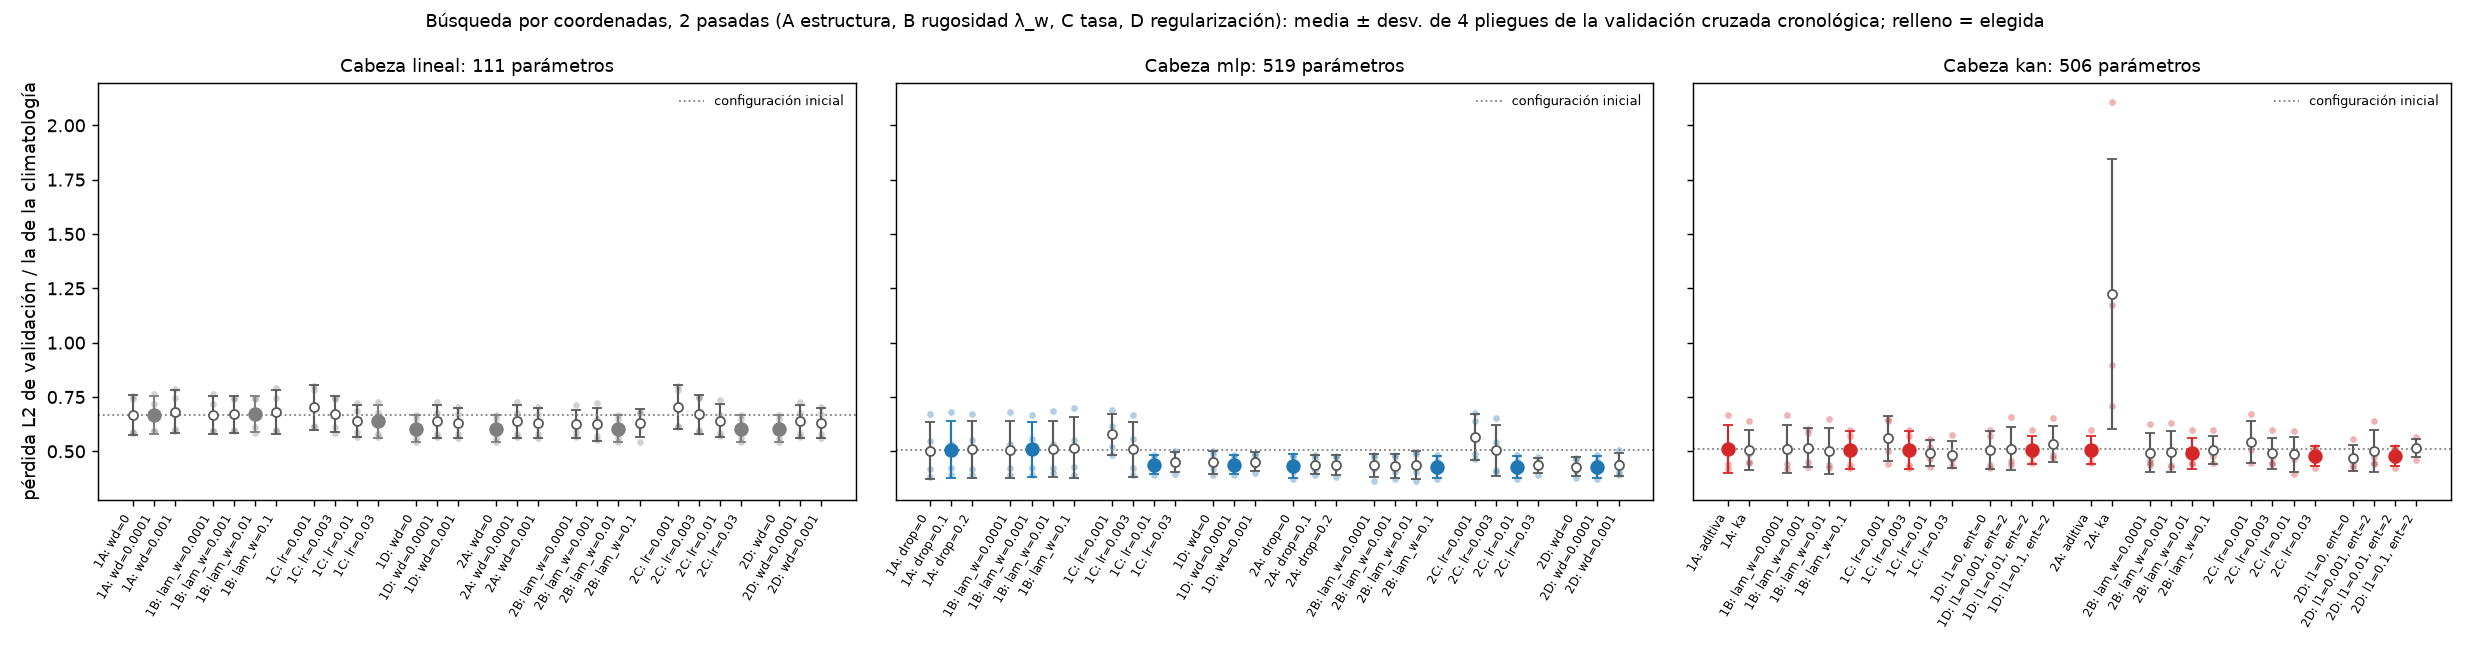

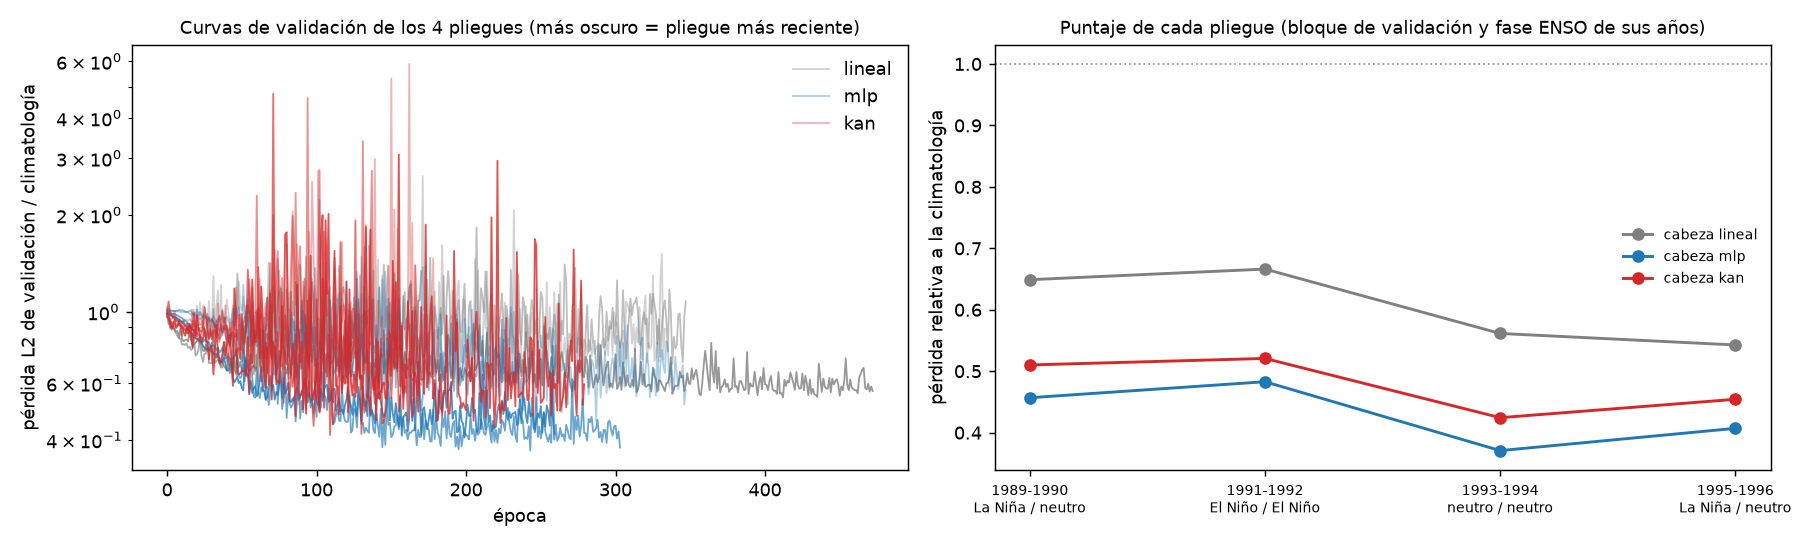

In [9]:
capacidad, esparsidad, fpca_fase = entrenamiento.diagnosticos(ctx)
display(capacidad, esparsidad, fpca_fase)
figura("busqueda_hiperparametros", "curvas_validacion")

## Evaluación

Cabeza lineal frente a la regresión funcional: máx |diferencia| = 1.89e-07


,tramo,modelo,curvas,estaciones,L2_rel,L2_IC,KGE,KGE_IC,PBIAS,PBIAS_IC,err_pico1_dias,err_pico1_IC,err_pico2_dias,err_pico2_IC,pct_truncado,sd_semillas_L2,parametros
0,prueba,Satélite sin corregir,789,121,0.494476,"[0.456, 0.539]",0.384070,"[0.331, 0.432]",2.428428,"[-5.5, 11.4]",23.858048,"[22.7, 25.0]",18.822560,"[17.8, 19.9]",0.000000,0.000000,0
1,prueba,Cabeza lineal,789,121,0.448822,"[0.424, 0.477]",0.438534,"[0.403, 0.468]",-6.007269,"[-12.4, 1.1]",20.213350,"[18.9, 21.6]",19.656950,"[18.8, 20.6]",0.049077,0.000515,111
2,prueba,Cabeza MLP,789,121,0.459379,"[0.430, 0.494]",0.408851,"[0.367, 0.446]",8.536693,"[3.7, 13.8]",21.957330,"[20.4, 23.3]",19.474018,"[18.5, 20.4]",0.003588,0.014004,519
3,prueba,Cabeza KAN,789,121,0.457153,"[0.432, 0.487]",0.428169,"[0.395, 0.456]",6.976778,"[2.5, 11.6]",22.590199,"[21.3, 23.8]",21.124630,"[20.2, 22.1]",0.000000,0.003593,506
4,ciegas,Satélite sin corregir,565,31,0.526061,"[0.469, 0.594]",0.305776,"[0.215, 0.383]",2.913012,"[-10.2, 19.7]",22.766372,"[20.3, 26.3]",20.302655,"[18.2, 22.5]",0.000000,0.000000,0
5,ciegas,Cabeza lineal,565,31,0.491471,"[0.434, 0.566]",0.347990,"[0.245, 0.432]",3.289123,"[-7.0, 17.2]",21.671386,"[18.3, 27.1]",19.504425,"[17.5, 21.8]",0.000000,0.000466,111
6,ciegas,Cabeza MLP,565,31,0.476779,"[0.395, 0.586]",0.356695,"[0.210, 0.469]",7.748674,"[-5.4, 21.1]",21.148673,"[17.8, 26.4]",19.400590,"[17.2, 21.9]",0.000000,0.002590,519
7,ciegas,Cabeza KAN,565,31,0.458470,"[0.387, 0.552]",0.393547,"[0.273, 0.492]",6.515282,"[-4.8, 18.2]",21.254867,"[18.5, 24.9]",19.399410,"[17.2, 21.9]",0.000000,0.000825,506


,tramo,comparacion,metrica,diferencia,IC95_inf,IC95_sup,IC_excluye_cero,p_bootstrap,wilcoxon_p,estaciones
0,prueba,Cabeza KAN - Cabeza lineal,L2_rel,0.007455,-0.008340,0.025081,False,0.330,6.313590e-01,121
1,prueba,Cabeza KAN - Cabeza lineal,KGE,-0.009530,-0.032800,0.011590,False,0.396,4.189101e-01,121
2,prueba,Cabeza KAN - Cabeza MLP,L2_rel,-0.002001,-0.013510,0.007949,False,0.658,5.136806e-01,121
3,prueba,Cabeza KAN - Cabeza MLP,KGE,0.018962,0.003332,0.036842,True,0.024,1.203621e-01,121
4,prueba,Cabeza KAN - Satélite sin corregir,L2_rel,-0.036042,-0.064782,-0.011547,True,0.004,6.609455e-02,121
5,prueba,Cabeza KAN - Satélite sin corregir,KGE,0.043152,0.010213,0.079590,True,0.008,1.191317e-01,121
6,prueba,Cabeza lineal - Satélite sin corregir,L2_rel,-0.043497,-0.073032,-0.022122,True,0.000,4.626385e-02,121
7,prueba,Cabeza lineal - Satélite sin corregir,KGE,0.052683,0.023213,0.089970,True,0.000,1.415154e-02,121
8,prueba,Cabeza MLP - Cabeza lineal,L2_rel,0.009456,-0.008817,0.030773,False,0.256,9.535905e-01,121
9,prueba,Cabeza MLP - Cabeza lineal,KGE,-0.028492,-0.058978,0.000096,False,0.054,1.292558e-01,121


,tramo,fase,curvas,modelo,L2_rel,KGE,PBIAS
0,prueba,nino,227,Satélite sin corregir,0.554039,0.351344,11.045211
1,prueba,nino,227,Cabeza lineal,0.480369,0.427454,-1.888718
2,prueba,nino,227,Cabeza MLP,0.465453,0.412471,3.706561
3,prueba,nino,227,Cabeza KAN,0.451596,0.477407,8.232890
4,prueba,nina,343,Satélite sin corregir,0.441366,0.414280,-5.390525
5,prueba,nina,343,Cabeza lineal,0.386426,0.490968,-17.224096
6,prueba,nina,343,Cabeza MLP,0.450032,0.398927,10.238154
7,prueba,nina,343,Cabeza KAN,0.436748,0.418627,4.971466
8,prueba,neutro,219,Satélite sin corregir,0.515920,0.370675,7.971351
9,prueba,neutro,219,Cabeza lineal,0.513848,0.367897,10.438462


,anio,fase,oni_medio,curvas,total_estacion_mm,total_satelite_mm,total_lineal_mm,total_mlp_mm,total_kan_mm,L2_satelite,PBIAS_satelite,L2_lineal,PBIAS_lineal,L2_mlp,PBIAS_mlp,L2_kan,PBIAS_kan
0,1997,nino,1.14,118,1604.369408,1787.004632,1924.715621,1557.835566,2005.878672,0.604614,11.383614,0.562031,19.967110,0.500117,-2.900444,0.545003,25.025986
1,1998,nina,0.04,118,1743.577993,1852.935059,1436.591109,1619.074896,1636.765312,0.485811,6.271992,0.382940,-17.606719,0.345796,-7.140667,0.371638,-6.126063
2,1999,nina,-1.08,116,2213.270437,1986.364386,1794.785169,2776.392596,2550.103893,0.384938,-10.252071,0.357552,-18.908004,0.550376,25.442989,0.472796,15.218812
3,2000,nina,-0.77,109,1709.183478,1511.423699,1461.677160,1854.069305,1762.258873,0.453305,-11.570424,0.420928,-14.480968,0.456089,8.476903,0.468870,3.105307
4,2001,neutro,-0.29,110,1498.160003,1656.117686,1732.101540,1807.744105,1794.046124,0.595345,10.543445,0.597785,15.615257,0.563549,20.664288,0.570827,19.749968
5,2002,nino,0.51,109,1588.409831,1757.975516,1178.808414,1762.038343,1427.512625,0.499287,10.675185,0.391965,-25.786885,0.427926,10.930964,0.350475,-10.129452
6,2003,neutro,0.24,109,1715.002585,1812.823852,1815.754264,1737.390200,1719.126027,0.435766,5.703855,0.429141,5.874725,0.371013,1.305398,0.418220,0.240434


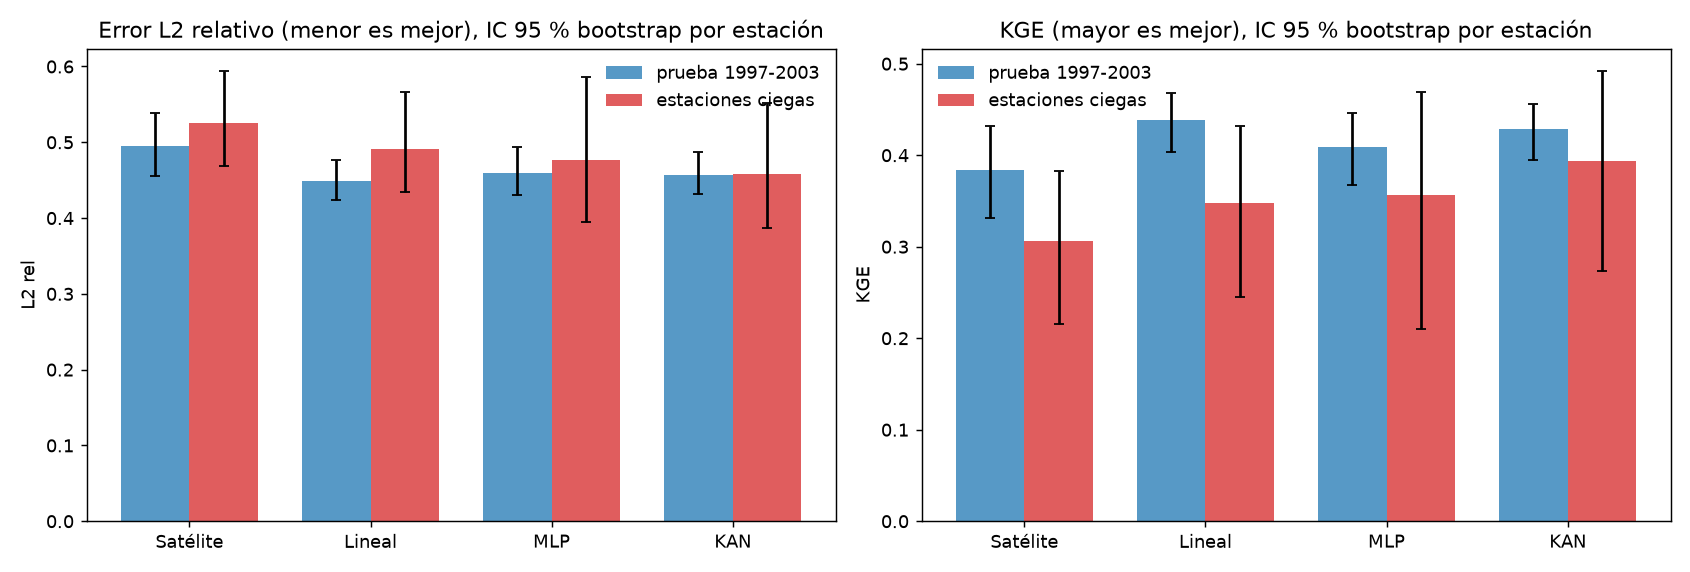

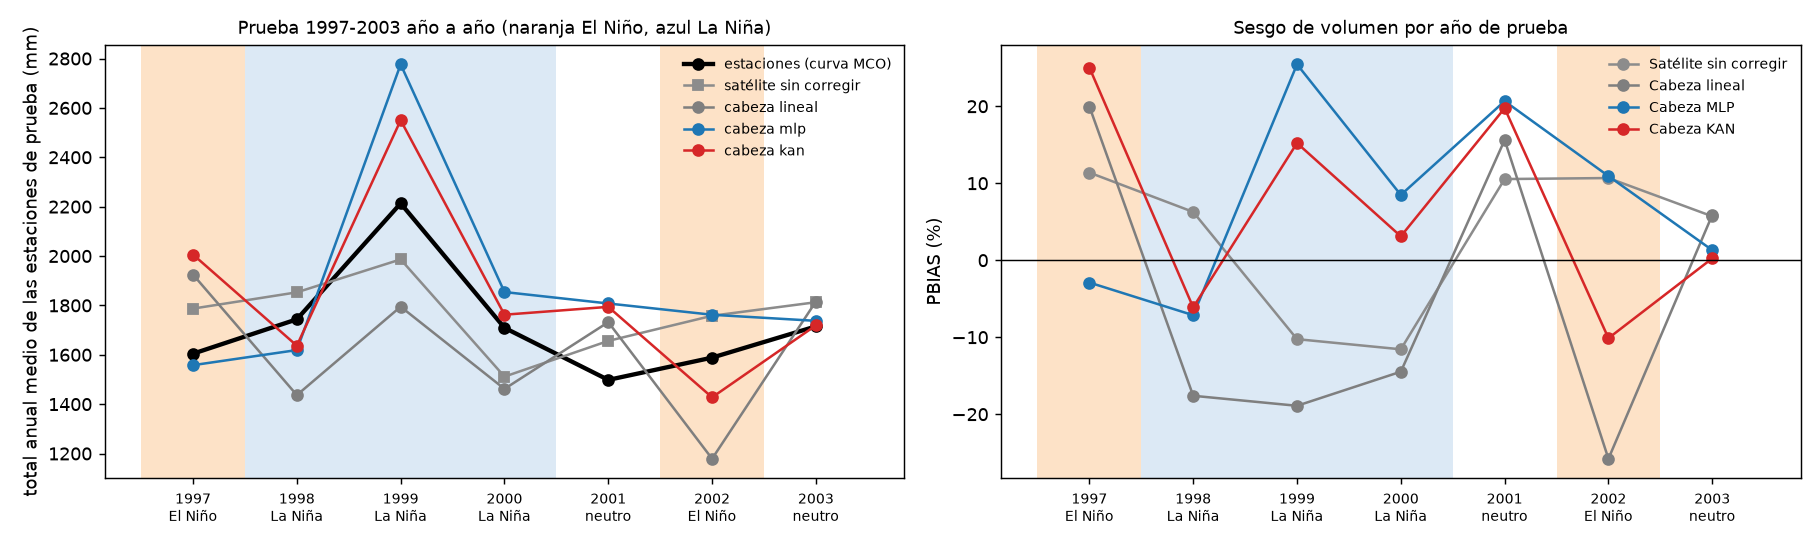

In [10]:
print(f"Cabeza lineal frente a la regresión funcional: máx |diferencia| = {evaluacion.equivalencia_lineal(ctx):.2e}")
tablas = evaluacion.evaluar(ctx)
display(tablas["maestra"], tablas["pareadas"], tablas["enso"], tablas["por_anio"])
figura("ablacion", "prueba_por_anio_enso")

## Predicciones

In [11]:
pred, sin_pred = evaluacion.predicciones(ctx)
print(f"{pred.station_id.nunique()} estaciones ciegas x {pred.year.nunique()} años x 365 días = {len(pred)} filas; sin predicción: {sin_pred}")
pred.head()

31 estaciones ciegas x 23 años x 365 días = 260245 filas; sin predicción: []


,station_id,year,day,value_mm
0,2610000104,1981,1,1.787
1,2610000104,1981,2,1.677
2,2610000104,1981,3,1.582
3,2610000104,1981,4,1.500
4,2610000104,1981,5,1.432


## Interpretación

entrada
z1             2.666667
z2             2.333333
z3             3.333333
z4             2.666667
z5             3.000000
z6             3.333333
altitud (m)    2.666667
ONI (°C)       5.000000
Name: aristas_activas_media, dtype: float64

,arista,criterio,expresion,R2,parametros,n_parametros,amplitud
2,s1 <- ONI (°C),ONI,a x^3 + b x^2 + c x + d,0.976985,"[0.7315, 1.2139, -4.0866, -0.0571]",4,10.785542
3,s1 <- ONI (°C),ONI,a sin(b x + c) + d,0.966614,"[-4.4592, 1.1159, 0.6057, 2.3976]",4,10.785542
1,s1 <- ONI (°C),ONI,a x^2 + b x + c,0.938553,"[1.4362, -2.8022, -0.1887]",3,10.785542
4,s1 <- ONI (°C),ONI,a tanh(b x + c) + d,0.909846,"[-4.8061, 1.0662, 0.778, 3.1069]",4,10.785542
0,s1 <- ONI (°C),ONI,a x + b,0.745054,"[-2.5113, 1.2221]",2,10.785542
5,s1 <- ONI (°C),ONI,a exp(b x) + c,0.745041,"[-66869.5773, 0.0, 66870.7994]",3,10.785542
10,s1 <- altitud (m),altitud,a tanh(b x + c) + d,0.867743,"[-6.7798, 6.6524, 9.7961, 3.3925]",4,19.236908
8,s1 <- altitud (m),altitud,a x^3 + b x^2 + c x + d,0.736785,"[-0.6471, 1.9391, 0.1173, -4.1303]",4,19.236908
9,s1 <- altitud (m),altitud,a sin(b x + c) + d,0.462357,"[4.4626, 1.8781, -0.8447, -1.2894]",4,19.236908
7,s1 <- altitud (m),altitud,a x^2 + b x + c,0.447708,"[0.6389, -2.4372, -2.0305]",3,19.236908


,cabeza,fase,oni,oni_neutro,cambio_total_anual_mm,cambio_pct,dias_con_aporte,dias_con_atenuacion,cambio_max_mm_dia,cambio_min_mm_dia
0,lineal,nina,-0.60,0.27,98.669132,5.405561,352,7,0.521074,-0.238032
1,lineal,nino,0.65,0.27,-41.250665,-2.259906,5,284,0.106698,-0.212438
2,mlp,nina,-0.60,0.27,378.166961,21.860160,363,1,1.630711,-0.051715
3,mlp,nino,0.65,0.27,-52.629804,-3.042296,3,303,0.117161,-0.293882
4,kan,nina,-0.60,0.27,364.407356,21.141897,358,5,1.551075,-0.445001
5,kan,nino,0.65,0.27,-227.153391,-13.178805,109,249,0.643530,-2.332185


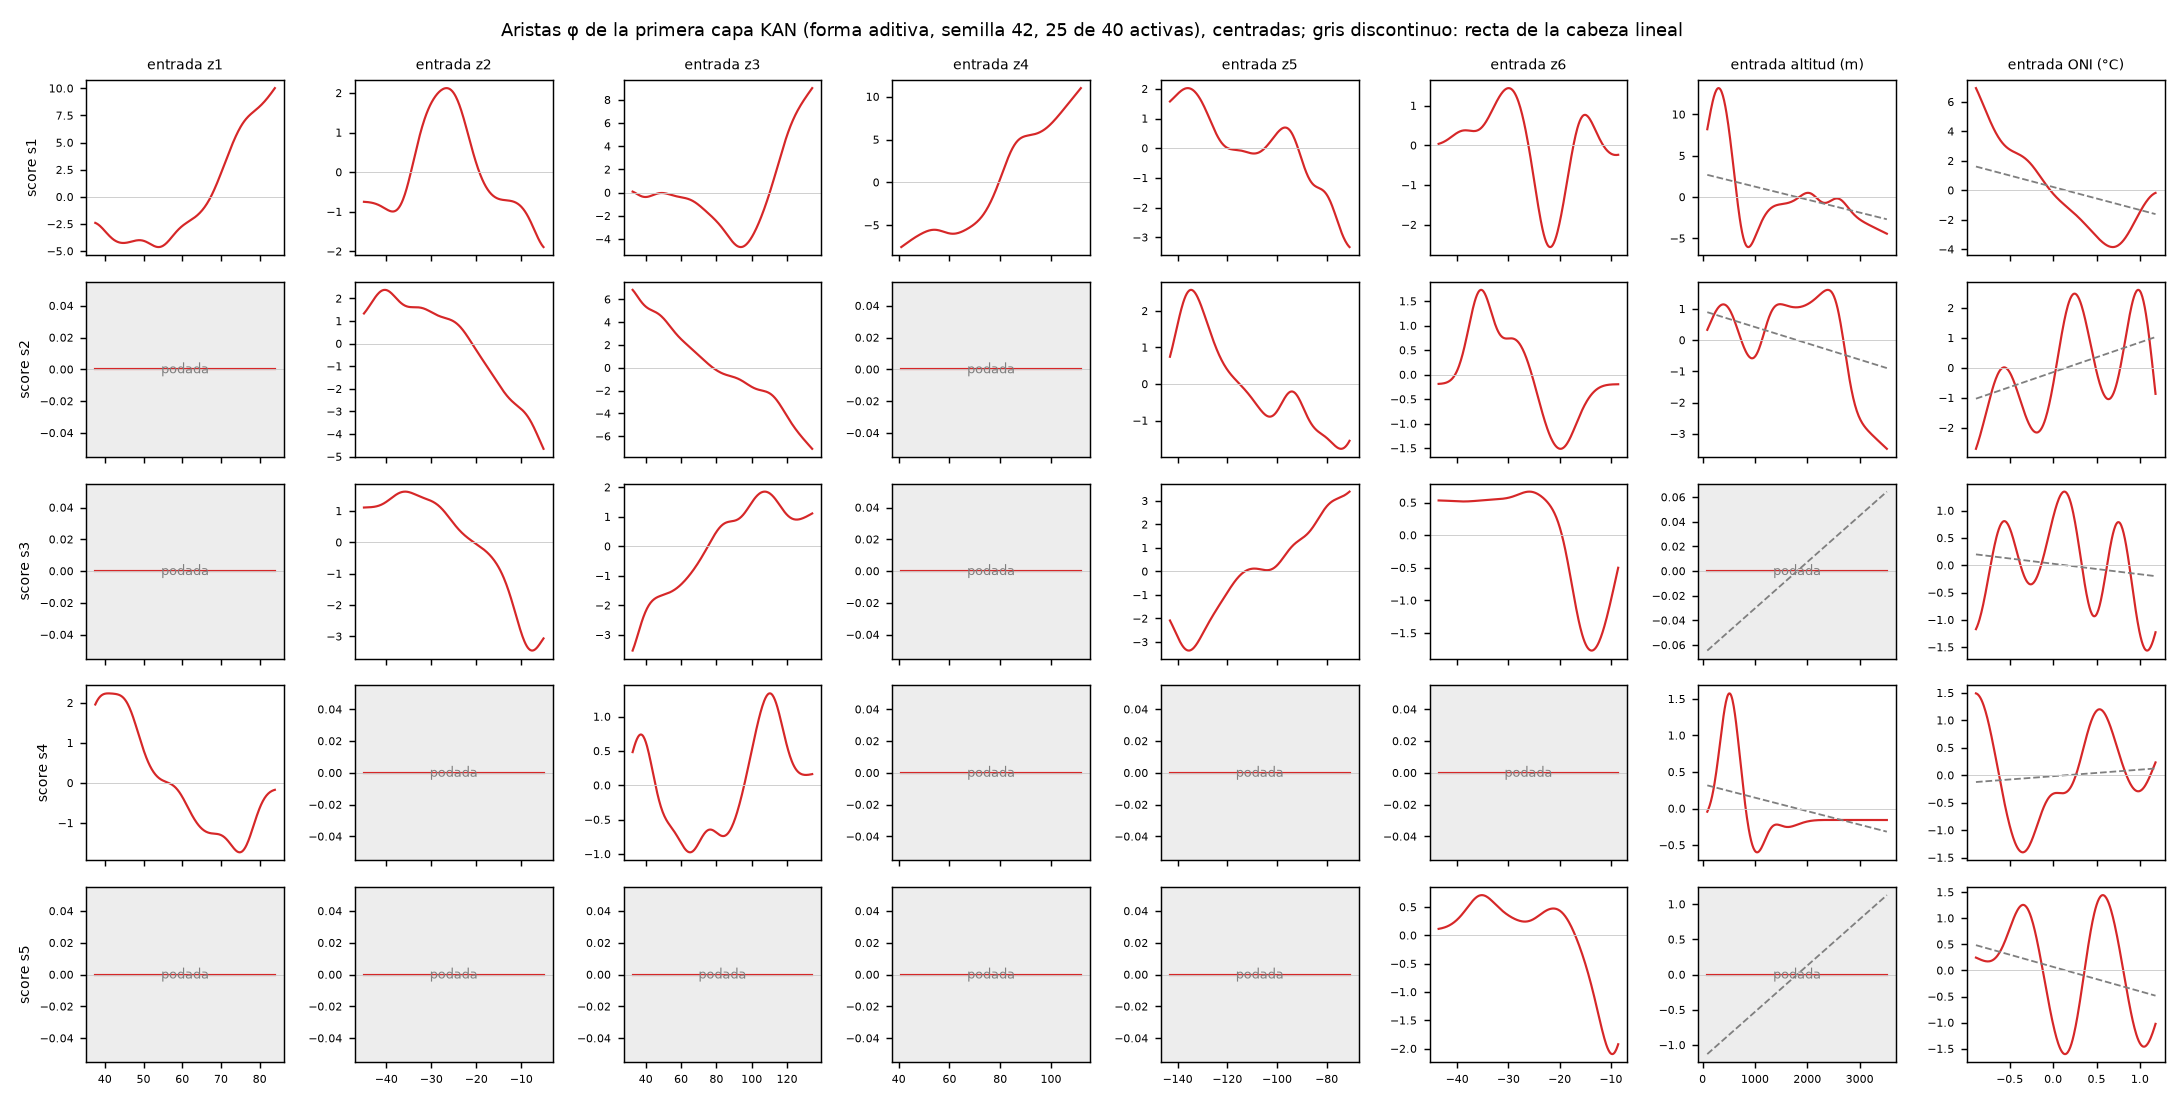

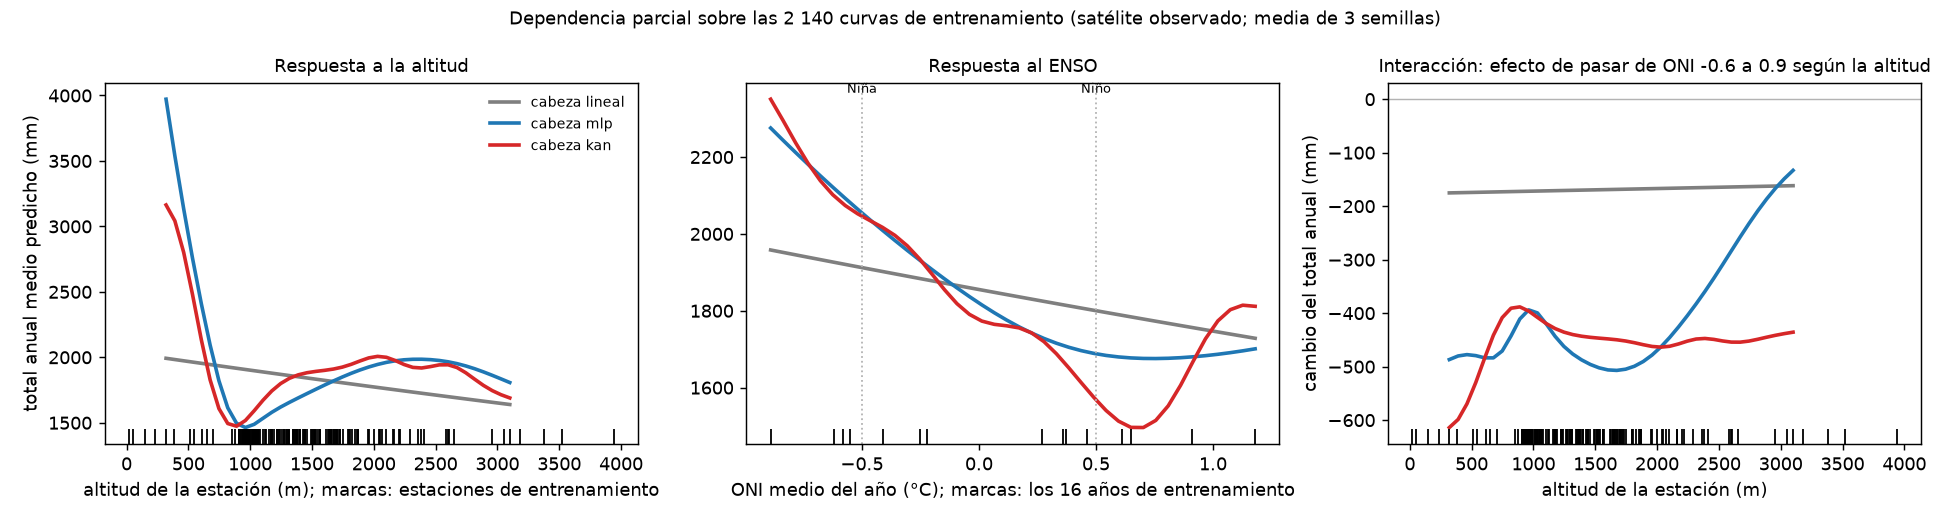

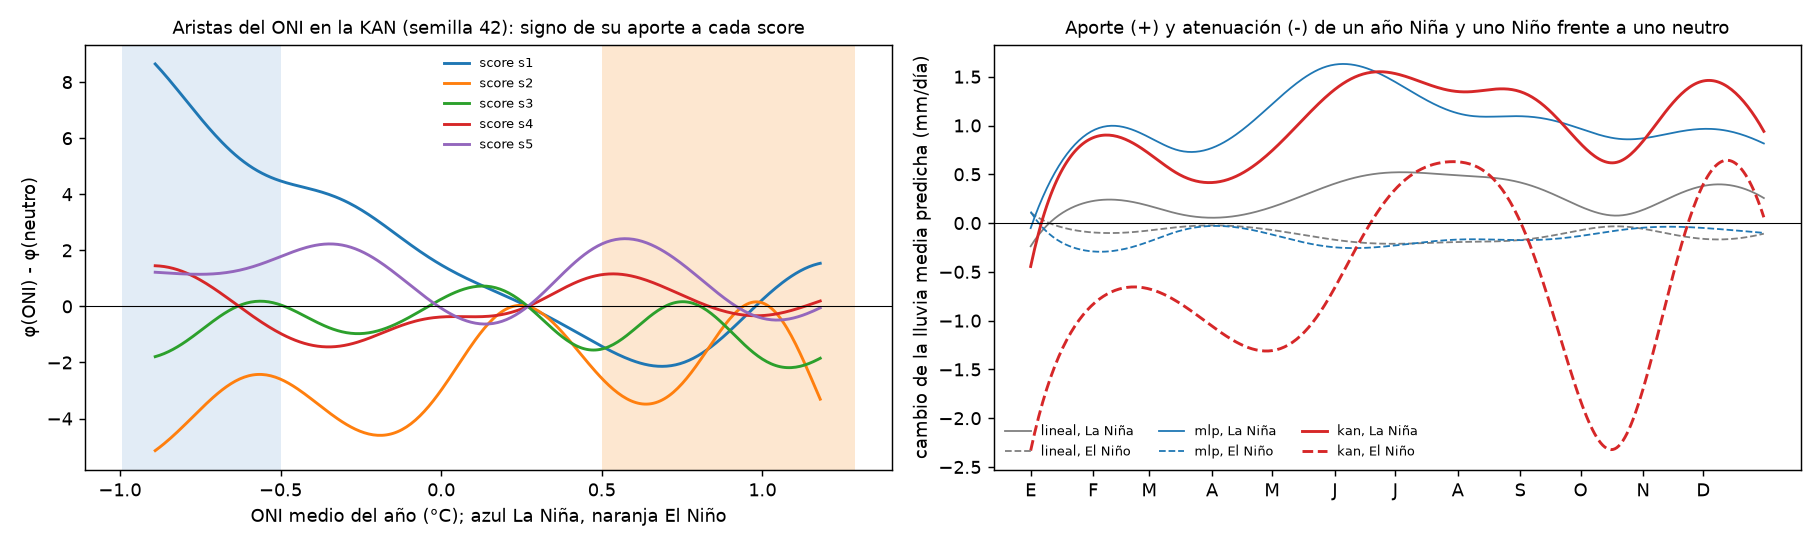

In [12]:
interp = interpretacion.interpretar(ctx)
display(interp["aristas"].groupby("entrada", sort=False).activa.sum().div(3).rename("aristas_activas_media"),
        interp["simbolico"], interp["aporte"])
figura("activaciones_kan", "dependencia_parcial", "aporte_atenuacion_enso")

### Aporte de cada covariable

lineal con satélite: listo


lineal con satélite + altitud: listo


lineal con satélite + ONI: listo


lineal con satélite + altitud + ONI: listo


mlp con satélite: listo


mlp con satélite + altitud: listo


... (3 outputs left out)

kan con satélite + altitud: listo


kan con satélite + ONI: listo


kan con satélite + altitud + ONI: listo


,cabeza,entradas,parametros,cv_rel_media,cv_rel_sd,prueba_L2,prueba_L2_IC,prueba_KGE,prueba_PBIAS,ciegas_L2,ciegas_L2_IC,ciegas_KGE,ciegas_PBIAS
0,lineal,satélite,101,0.637250,0.095970,0.466016,"[0.444, 0.494]",0.420198,-6.508617,0.504423,"[0.439, 0.587]",0.339563,4.145545
1,lineal,satélite + altitud,106,0.611641,0.033035,0.464331,"[0.440, 0.493]",0.418220,-6.640794,0.498738,"[0.441, 0.575]",0.337422,3.369767
2,lineal,satélite + ONI,106,0.614045,0.072520,0.454193,"[0.432, 0.482]",0.436163,-5.879765,0.495684,"[0.431, 0.576]",0.350895,4.132412
3,lineal,satélite + altitud + ONI,111,0.604836,0.061802,0.448822,"[0.424, 0.477]",0.438534,-6.007269,0.491471,"[0.434, 0.566]",0.347990,3.289123
4,mlp,satélite,455,0.530495,0.090478,0.436893,"[0.413, 0.466]",0.452319,1.287324,0.468771,"[0.411, 0.539]",0.375842,8.765779
5,mlp,satélite + altitud,487,0.439288,0.038232,0.419038,"[0.396, 0.447]",0.461344,0.258724,0.471071,"[0.390, 0.580]",0.361188,6.624977
6,mlp,satélite + ONI,487,0.525209,0.097499,0.482717,"[0.451, 0.519]",0.391050,9.512742,0.478500,"[0.416, 0.552]",0.364719,9.855347
7,mlp,satélite + altitud + ONI,519,0.429416,0.050167,0.459379,"[0.430, 0.494]",0.408851,8.536693,0.476779,"[0.395, 0.586]",0.356695,7.748674
8,kan,satélite,396,0.510975,0.032975,0.456773,"[0.431, 0.488]",0.421094,1.480937,0.470358,"[0.410, 0.541]",0.370665,8.346290
9,kan,satélite + altitud,451,0.479820,0.066798,0.438031,"[0.415, 0.465]",0.448662,2.138557,0.458174,"[0.389, 0.547]",0.380470,5.650891


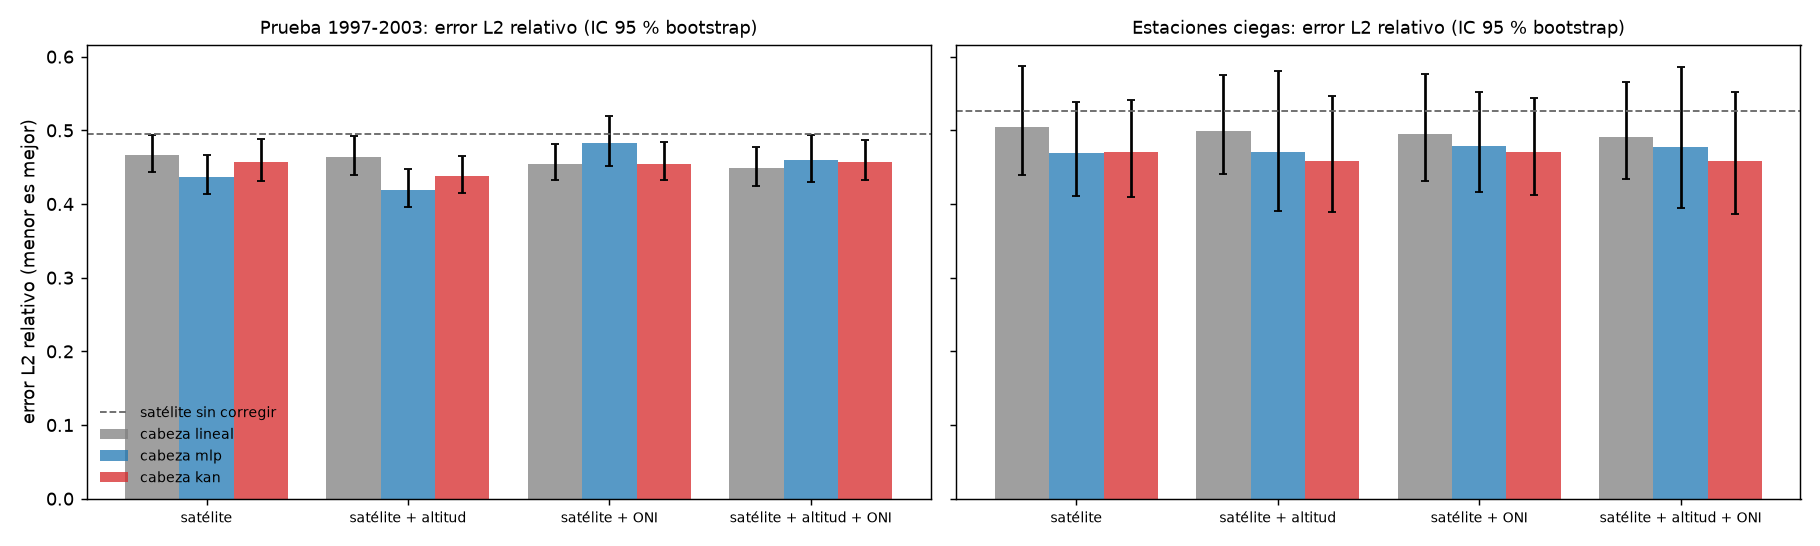

In [13]:
ablacion = evaluacion.ablacion_covariables(ctx)
display(ablacion)
figura("ablacion_covariables")

### Cabeza lineal, autofunciones y peores casos

In [14]:
interpretacion.complementos(ctx)

,station_id,year,altitud_m,fase,total_estacion_mm,total_satelite_mm,L2_rel_kan
0,5301100101,1982,11.3,nino,3223.000000,5675.154793,2.524736
1,2612800104,1991,1555.0,nino,303.662165,1127.685765,2.509464
2,2614100104,1992,1956.0,nino,493.000000,1501.038161,2.065954
3,2614100104,2001,1956.0,neutro,522.501937,1387.899302,2.056826


## Verificaciones

In [15]:
evaluacion.verificaciones(ctx)

Tiempo total: 9.2 min


,verificacion,valor,tolerancia,cumple
0,Coordenadas CVC datos.gov.co vs consigna: dist...,3.963766e-02,1.000000e-01,True
1,Altitud IDEAM datos.gov.co vs consigna: |difer...,0.000000e+00,1.000000e+01,True
2,"Altitud SRTM (CGIAR, 90 m) vs consigna: |difer...",4.560000e+01,5.000000e+01,True
3,Estaciones del Valle sin altitud tras consigna...,0.000000e+00,0.000000e+00,True
4,Gram W (Gauss-Legendre) frente al trapecio fin...,5.038263e-08,1.000000e-06,True
5,"Ortonormalidad de las autofunciones, máx|Psi W...",1.776357e-15,1.000000e-10,True
6,RMSE de la KAN sintética en 1 000 puntos de va...,8.270983e-03,1.000000e-02,True
7,Discrepancia de parámetros KAN frente a MLP (m...,2.504817e-02,1.000000e-01,True
8,max_t |y_red_lineal - y_regresion_funcional| (...,1.891725e-07,1.000000e-04,True
9,Valores negativos en el CSV de predicciones,0.000000e+00,0.000000e+00,True


## Tablas en memoria

Los diagnósticos, las validaciones, la trazabilidad y las tablas de resultados de la red no se escriben en disco: quedan en `ctx.preproceso` (preprocesamiento, solo si se rehízo en esta corrida) y en `ctx.tablas` (red funcional), con el nombre del archivo que las guardaba antes.

In [ ]:
print("Preprocesamiento:", ", ".join(sorted(ctx.preproceso)) or "se reutilizó data/processed/, sin tablas de diagnóstico")
print("Red funcional:", ", ".join(sorted(ctx.tablas)))
if ctx.preproceso:
    display(ctx.preproceso["tabla_trazabilidad"], ctx.preproceso["prueba_fuga"]["comprobaciones"])